<a href="https://colab.research.google.com/github/bookwork123/MachineLearning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

**Task 1: Load the dataset into a Pandas DataFrame.**

The first code block contains a terminal command to install ucimlrepo, so that I can programatically fetch the dataset.

The second code block contains the code that actually fetches the dataset using the previous import. Then, I load it into a Pandas DataFrame.

In [3]:
!pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo
heart_disease = fetch_ucirepo(id=45)
df = heart_disease.data.original

In [5]:
X = heart_disease.data.features
y = heart_disease.data.targets

**Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.**

Each of the following commands is used to inspect the dataset and familiarize myself with its structure.

In [6]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2.0,3.0,3
7,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1.0,7.0,2
9,53,1,4,140,203,1,2,155,1,3.1,3,0.0,7.0,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [8]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


**Task 3: Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.**



The first code block checks for the '?' non-standard placeholder and determines that there are 0, so we don't have to worry about this.

In the second block, I check how many true null values we have across each column. In two columns (ca, thal) there are missing values. Both of these columns contain discrete integer values, so I will impute using the 'most_frequent' strategy.

In the third block, I use SimpleImputer to impute the most frequent values where there are null values in 'ca' and 'thal.'

In the fourth block, I confirm that we no longer have any null values.

In [9]:
(df == '?').sum().sum()

np.int64(0)

In [10]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [11]:
imputer = SimpleImputer(strategy='most_frequent')
df['ca'] = imputer.fit_transform(df[['ca']])
df['thal'] = imputer.fit_transform(df[['thal']])

In [12]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


**Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.**

In the first block, I separate the columns into numeric and categorical columns. Although the assignment flags 'ca' as categorical, it is considered numeric by the dataset, and actually is used to count values and can be acted upon in a numeric/quantitative fashion.

In the second block, I create a numeric and a categorical transformer to conduct scaling and encoding.

In the third and fourth blocks, I combine the transformers and create a Pipeline to process them.

In [13]:
numeric_features = ['age', 'trestbps','chol','thalach','oldpeak','ca']
categorical_features = ['sex','cp','fbs','restecg','exang','slope','thal']

In [14]:
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [16]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
])

**Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.**

In the first code block, I turn the target variable into a true binary (0,1) for better training, then make my train/test splits and print the shape of each set.

In the second block, I redo my numeric + categorical pipeline to ensure imputation and scaling takes place.

In the third block, I run the full pipeline tuned to SVC.

The fourth, fifth, and sixth blocks create and display the classification report, confusion matrix, and ROC-AUC curve, respectively.

In [17]:
# Collapse the 0–4 severity scale into absence (0) / presence (1) of heart disease
y_binary = (y['num'] > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}")

Training set shape: (242, 13)
Testing set shape: (61, 13)
Class distribution in y_train:
num
0    0.541322
1    0.458678
Name: proportion, dtype: float64


In [18]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [19]:
pipeline_svc = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('svc', SVC(C=1.0, kernel='rbf', probability=True, random_state=42))
])

pipeline_svc.fit(X_train, y_train)

y_pred_svc = pipeline_svc.predict(X_test)
y_proba_svc = pipeline_svc.predict_proba(X_test)[:, 1]  # probability of class 1 (disease)

In [20]:
print("SVC Classification Report:")
print(classification_report(y_test, y_pred_svc, target_names=['No Disease', 'Disease']))

SVC Classification Report:
              precision    recall  f1-score   support

  No Disease       0.94      0.88      0.91        33
     Disease       0.87      0.93      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61



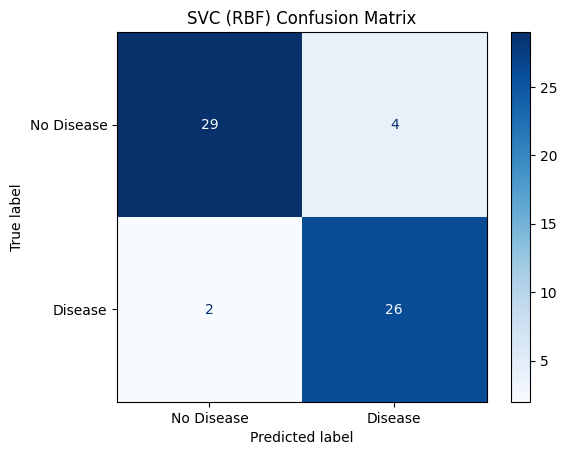

In [21]:
cm_svc = confusion_matrix(y_test, y_pred_svc)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc, display_labels=['No Disease', 'Disease'])
disp.plot(cmap='Blues')
plt.title('SVC (RBF) Confusion Matrix')
plt.show()

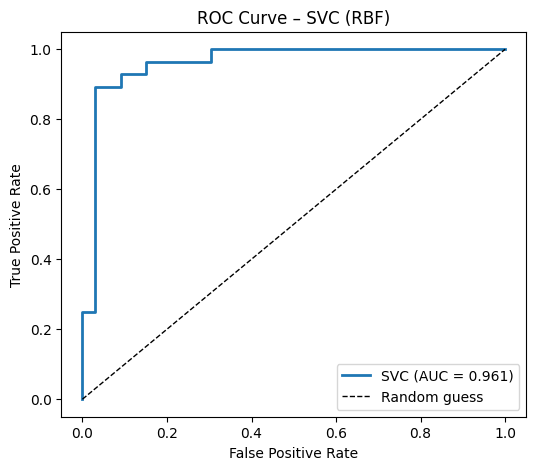

In [22]:
fpr_svc, tpr_svc, _ = roc_curve(y_test, y_proba_svc)
roc_auc_svc = auc(fpr_svc, tpr_svc)

plt.figure(figsize=(6, 5))
plt.plot(fpr_svc, tpr_svc, lw=2, label=f'SVC (AUC = {roc_auc_svc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – SVC (RBF)')
plt.legend(loc='lower right')
plt.show()

**Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.**

The first code block creates and runs a new Pipeline tuned to the Decision Tree Classifier.

The second block prints the classification report.

The third block creates a confusion matrix, and recreates the SVC confusion matrix so that the two can be directly compared.

In the fourth block, I display the ROC-AUC curve for the Decision Tree Classifier-trained model and the SVC model.

In [23]:
pipeline_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('dt', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42))
])

pipeline_dt.fit(X_train, y_train)

y_pred_dt = pipeline_dt.predict(X_test)
y_proba_dt = pipeline_dt.predict_proba(X_test)[:, 1]  # probability of class 1 (disease)

In [24]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt, target_names=['No Disease', 'Disease']))

Decision Tree Classification Report:
              precision    recall  f1-score   support

  No Disease       0.83      0.73      0.77        33
     Disease       0.72      0.82      0.77        28

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.78      0.77      0.77        61



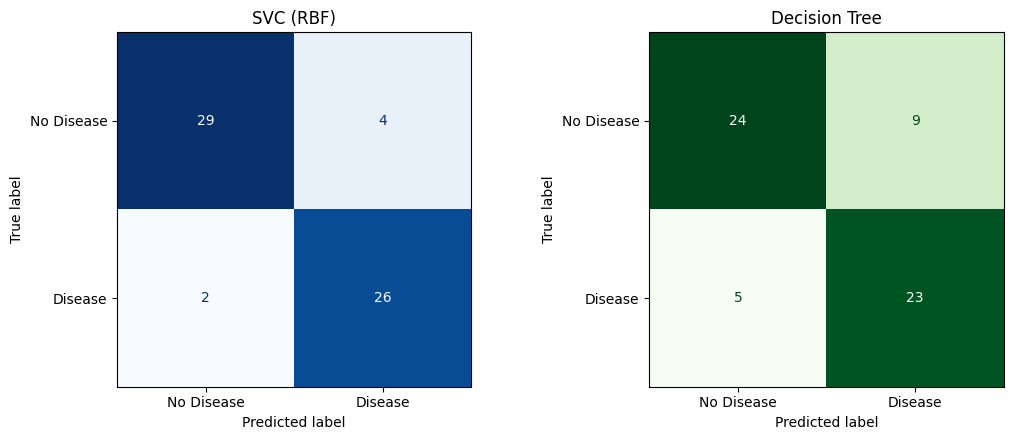

In [25]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm_svc, display_labels=['No Disease', 'Disease']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('SVC (RBF)')
ConfusionMatrixDisplay(cm_dt, display_labels=['No Disease', 'Disease']).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Decision Tree')
plt.tight_layout()
plt.show()

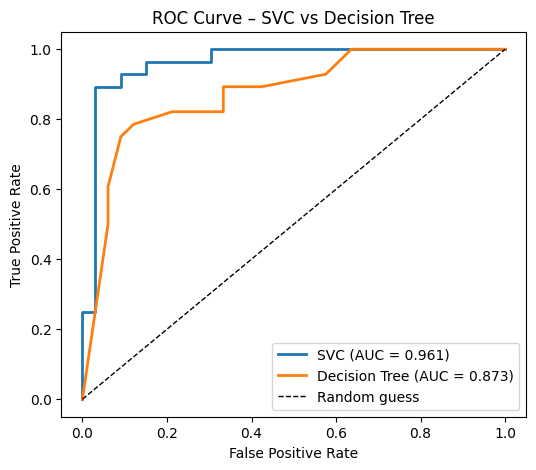

In [26]:
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(6, 5))
plt.plot(fpr_svc, tpr_svc, lw=2, label=f'SVC (AUC = {roc_auc_svc:.3f})')
plt.plot(fpr_dt, tpr_dt, lw=2, label=f'Decision Tree (AUC = {roc_auc_dt:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – SVC vs Decision Tree')
plt.legend(loc='lower right')
plt.show()

**Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.**

In the first code block, I run 5-fold cross-validation on the default SVC from Task 5 to get a baseline score to compare against.

In the second block, I use GridSearchCV to test different combinations of C and gamma, and print the combination with the best cross-validation accuracy.

In the third block, I compare the tuned SVC’s training and validation accuracy across each of the 5 folds to check for overfitting.

In [36]:
# 5-fold CV accuracy of the default SVC (C=1.0, gamma='scale') from Task 5, for comparison
baseline_cv_scores = cross_val_score(pipeline_svc, X_train, y_train, cv=5)

print("Baseline SVM Cross-Validation Accuracy Scores:", baseline_cv_scores)
print(f"Mean Baseline SVM CV Accuracy: {baseline_cv_scores.mean():.4f} (+/- {baseline_cv_scores.std() * 2:.4f})")

Baseline SVM Cross-Validation Accuracy Scores: [0.91836735 0.79591837 0.8125     0.75       0.8125    ]
Mean Baseline SVM CV Accuracy: 0.8179 (+/- 0.1104)


In [37]:
param_grid = {
    'svc__C': [0.01, 0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(pipeline_svc, param_grid, cv=5,
                           scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_svc = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(f"Best Mean CV Accuracy: {grid_search.best_score_:.4f}")

Best parameters: {'svc__C': 1, 'svc__gamma': 0.01}
Best Mean CV Accuracy: 0.8429


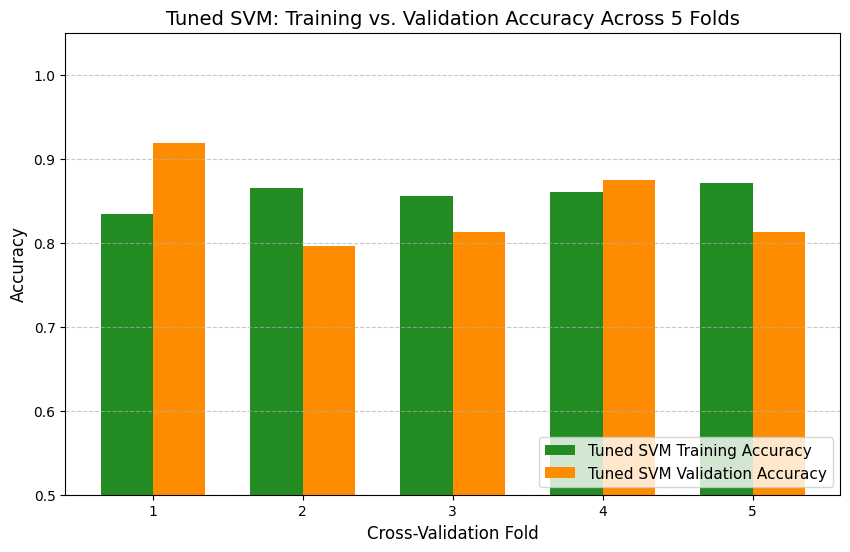

Tuned SVM Fold-by-fold Training Accuracies: [0.8342 0.8653 0.8557 0.8608 0.8711]
Tuned SVM Fold-by-fold Validation Accuracies: [0.9184 0.7959 0.8125 0.875  0.8125]


In [38]:
best_cv_results = cross_validate(best_svc, X_train, y_train, cv=5, return_train_score=True)

best_train_scores = best_cv_results['train_score']
best_val_scores = best_cv_results['test_score']
folds = np.arange(1, 6)
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(folds - width/2, best_train_scores, width, label='Tuned SVM Training Accuracy', color='forestgreen')
plt.bar(folds + width/2, best_val_scores, width, label='Tuned SVM Validation Accuracy', color='darkorange')

plt.xlabel('Cross-Validation Fold', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Tuned SVM: Training vs. Validation Accuracy Across 5 Folds', fontsize=14)
plt.xticks(folds)
plt.ylim(0.50, 1.05)
plt.legend(loc='lower right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("Tuned SVM Fold-by-fold Training Accuracies:", np.round(best_train_scores, 4))
print("Tuned SVM Fold-by-fold Validation Accuracies:", np.round(best_val_scores, 4))

**Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.**

In the first code block, I create a new Decision Tree with a limited depth and a minimum number of samples per leaf to prevent overfitting, then train it on the training data.

In the second block, I get the names of every feature after preprocessing, so that the tree diagram shows readable labels.

In the third block, I plot the decision tree to show which features the model uses to separate patients with heart disease from healthy patients.

In [33]:
# Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
dt_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('dt', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42))
])

# Fit the model on the full training data
dt_clf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'thal'])])),
                ('dt',
                 DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                                        random_state=42))])

In [34]:
# Extract feature names from the preprocessor step
cat_encoder = dt_clf.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

# Combine numerical and encoded categorical feature names
all_feature_names = numeric_features + encoded_cat_features
print(f"Total features after preprocessing: {len(all_feature_names)}")
print(all_feature_names)

Total features after preprocessing: 25
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex_0.0', 'sex_1.0', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'fbs_0.0', 'fbs_1.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'exang_0.0', 'exang_1.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


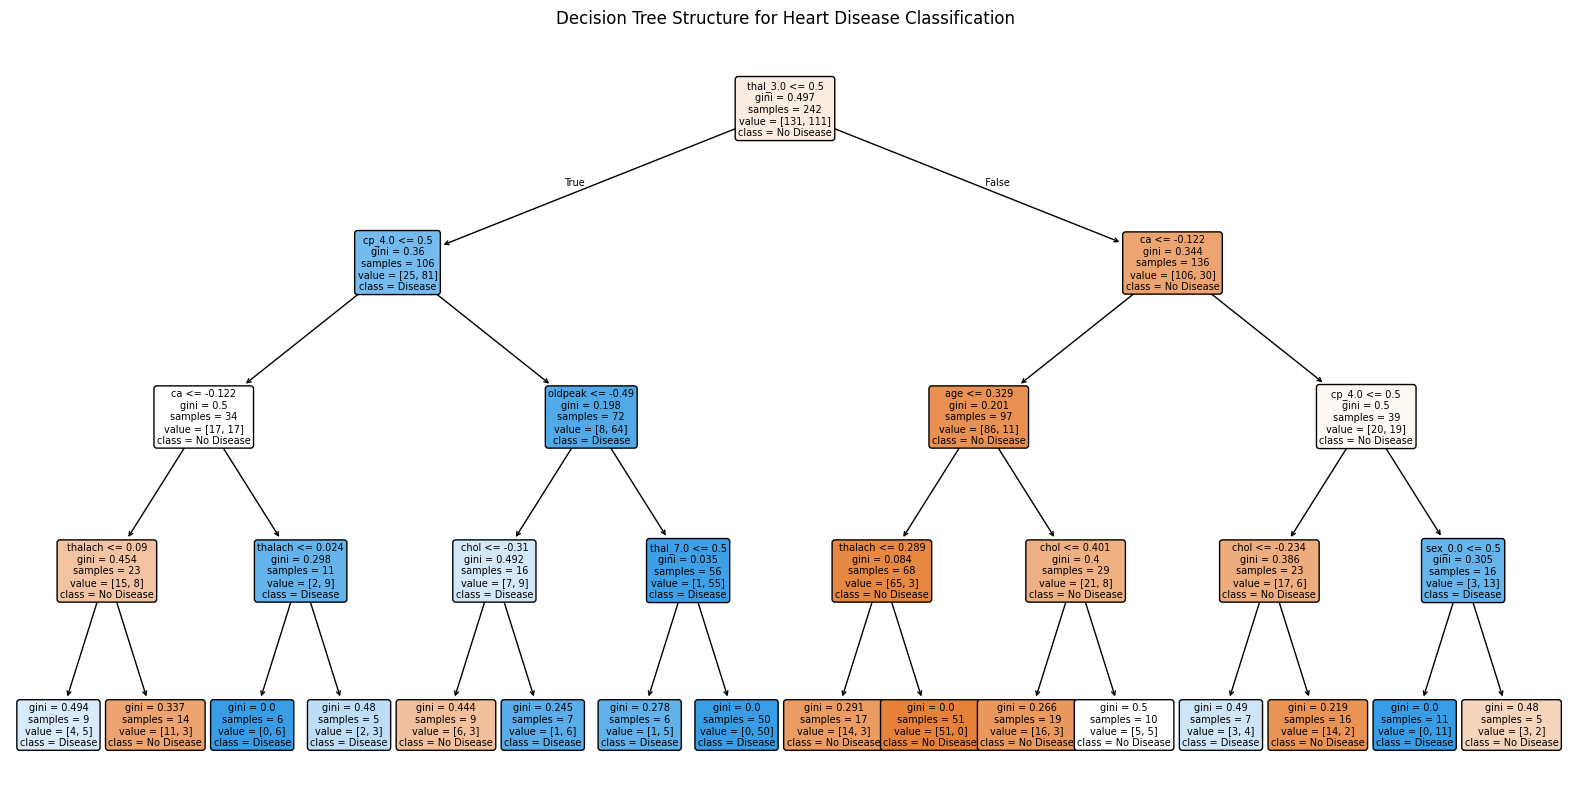

In [40]:
# Plot the trained decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_clf.named_steps['dt'],
    feature_names=all_feature_names,
    class_names=['No Disease', 'Disease'],
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Decision Tree Structure for Heart Disease Classification")
plt.show()